# Parte 1: dataset y preprocesamiento

**Notebook en Colab:** LO DEJAMOS PENDIENTE PARA CUANDO LO SUBAMOS

## Equipo
- Alumno 1 : Lucas Ramirez 
- Alumno 2 : Valentín Lujambio

## 0. Configuración

El código reutilizable vive en `src/lib/` y se importa desde acá, desde la notebook 2 y desde el backend. Las semillas se fijan una sola vez.

**En Colab:** clonar el fork (`!git clone ... && %cd tuia-face-recognition-app`), instalar `!pip install -r requirements.txt` y ejecutar desde la raíz del repo.

In [4]:
import random
import shutil
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from lib.dataset.inspection import inspect_files
from lib.dataset.sources import FolderDataset, filter_min_images, find_dataset_root, strip_prefix

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATA_DIR = ROOT / "data"          # data/* está en .gitignore: las imágenes no se suben
RAW_DIR = DATA_DIR / "raw" / "pins"

In [5]:
def show_grid(images_bgr, titles=None, ncols=8, size=1.8, suptitle=None):
    """Grilla de imágenes BGR (se convierten a RGB solo para mostrarlas)."""
    n = len(images_bgr)
    nrows = max(1, int(np.ceil(n / ncols)))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size * 1.15), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, img, i in zip(axes.flat, images_bgr, range(n)):
        if img is not None:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        if titles is not None:
            ax.set_title(titles[i], fontsize=7)
    if suptitle:
        fig.suptitle(suptitle)
    plt.tight_layout()
    plt.show()

## 2.1 Elección del dataset

Elegimos **Pins Face Recognition** (Kaggle, `hereisburak/pins-face-recognition`): 105 celebridades y 17.534 imágenes recolectadas de Pinterest, una carpeta por persona. Los números exactos salen de la celda de carga.

| Opción | A favor | En contra |
|---|---|---|
| **Pins** (elegido) | Pocas personas con muchas fotos cada una, que es lo que necesita una CNN entrenada desde cero (modelo A): aprende a reconocer a alguien viendo muchas variaciones de esa misma persona. Alcanza para separar identidades enteras para open-set. | Pocas identidades. Fotos de celebridades: producción profesional, maquillaje, sesgo demográfico probable. |
| LFW | Protocolo oficial de pares; es el de la práctica de la cátedra. | La mayoría de las 5.749 personas tiene una sola foto. Con ≥ 20 fotos quedan ~62 personas y ~3.000 imágenes, muy desbalanceado. |
| CelebA / CASIA-WebFace | Muchas identidades y variedad. | Pesados; CASIA tiene ruido de etiquetas. |

**Relación con la app:** la app registra pocas personas con pocas fotos y reconoce caras nuevas. Lo que más importa es que el embedding generalice a identidades no vistas, y Pins permite medirlo separando identidades (2.7).

**Limitaciones y cómo pueden afectar:**
- **Dominio:** fotos de prensa y redes de celebridades. La app va a recibir fotos de celular o webcam, con peor luz y resolución, así que el rendimiento real puede ser menor que el medido.
- **Pocas identidades:** con ~105 personas, la verificación open-set se mide sobre pocas identidades y pocos pares impostores distintos, lo que hace las métricas a FAR bajo (1e-3) poco estables.
- **Sesgo demográfico:** se analiza en 2.8.
- **Etiquetas:** al ser recolectado de la web puede haber fotos mal etiquetadas o con otra persona; lo auditamos en 2.5.

**Licencia:** en Kaggle el dataset figura como **CC0: Public Domain** (dato de la API de Kaggle, `licenseName`), lo que permite el uso académico. La descripción aclara que las imágenes fueron recolectadas de Pinterest y recortadas (105 celebridades, 17.534 caras). Hay un matiz: la licencia CC0 la declara quien subió el dataset, pero los derechos de cada foto son de sus autores originales, y las personas fotografiadas no dieron consentimiento para este uso. Lo retomamos en 2.8.

### Descarga y carga

Se descarga con `kagglehub` (viene instalado en Colab; local: `pip install kagglehub`). Requiere un token de Kaggle (`~/.kaggle/kaggle.json` o las variables `KAGGLE_USERNAME` y `KAGGLE_KEY`). Alternativa manual: bajar el zip desde la página del dataset y descomprimirlo en `data/raw/pins/`.

`FolderDataset` lee cualquier dataset con una carpeta por identidad, así el resto de la notebook no depende de Pins. Las carpetas de Pins se llaman `pins_<Nombre>`: `strip_prefix` deja solo el nombre.

In [6]:
if not RAW_DIR.exists():
    import kagglehub
    from dotenv import load_dotenv
    load_dotenv(ROOT / "src" / ".env")   # KAGGLE_API_TOKEN, si no está en ~/.kaggle/access_token
    downloaded = Path(kagglehub.dataset_download("hereisburak/pins-face-recognition"))
    shutil.copytree(downloaded, RAW_DIR)

DATASET_ROOT = find_dataset_root(RAW_DIR)
dataset = FolderDataset(DATASET_ROOT, label_parser=strip_prefix("pins_")).to_frame()
print(f"Raíz del dataset: {DATASET_ROOT.relative_to(ROOT)}")
print(f"Identidades: {dataset['identity'].nunique()} | Imágenes: {len(dataset)}")
dataset.head()

c:\Valentin\Personales\UNR\Vision por computadora\TP_1\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 372M/372M [00:13<00:00, 28.2MB/s] 

Extracting files...


Raíz del dataset: data\raw\pins\105_classes_pins_dataset
Identidades: 105 | Imágenes: 17534


,path,identity,extension
0,pins_Adriana Lima/Adriana Lima0_0.jpg,Adriana Lima,.jpg
1,pins_Adriana Lima/Adriana Lima101_3.jpg,Adriana Lima,.jpg
2,pins_Adriana Lima/Adriana Lima102_4.jpg,Adriana Lima,.jpg
3,pins_Adriana Lima/Adriana Lima103_5.jpg,Adriana Lima,.jpg
4,pins_Adriana Lima/Adriana Lima104_6.jpg,Adriana Lima,.jpg


## 2.2 Análisis exploratorio (EDA)

### Imágenes por identidad y desbalance

mean       167.0
mediana    169.0
min         86.0
max        237.0
Desbalance (máx / mín): 2.8×


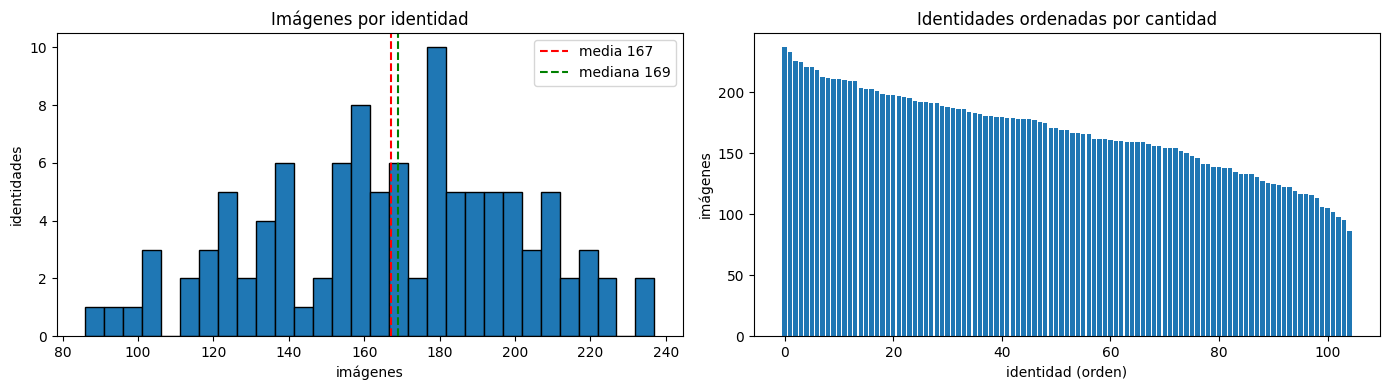

In [7]:
counts = dataset["identity"].value_counts()
stats = counts.describe()[["mean", "50%", "min", "max"]].rename({"50%": "mediana"})
print(stats.round(1).to_string())
print(f"Desbalance (máx / mín): {counts.max() / counts.min():.1f}×")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(counts, bins=30, edgecolor="black")
axes[0].axvline(counts.mean(), color="red", ls="--", label=f"media {counts.mean():.0f}")
axes[0].axvline(counts.median(), color="green", ls="--", label=f"mediana {counts.median():.0f}")
axes[0].set(title="Imágenes por identidad", xlabel="imágenes", ylabel="identidades")
axes[0].legend()
axes[1].bar(range(len(counts)), counts.values)
axes[1].set(title="Identidades ordenadas por cantidad", xlabel="identidad (orden)", ylabel="imágenes")
plt.tight_layout()
plt.show()

El enunciado sugiere un mínimo de 10 a 20 imágenes por identidad para la CNN custom. Fijamos **20**: además de entrenar, cada identidad del closed-set tiene que aportar imágenes a train, validación y test (15% + 15%), y con 20 imágenes eso son al menos 3 por split.

El desbalance es moderado. Las identidades tienen entre ~86 y ~237 imágenes (≈2,8×), con media 167 y mediana 169. Media y mediana casi iguales indican una distribución simétrica, sin identidades con muy pocas fotos. Todas superan ampliamente el mínimo de 20, así que el filtro no descarta ninguna. Al estar en el límite del criterio de 2-3×, el desbalance no justifica por sí solo técnicas de rebalanceo; en 2.6 se deja planteada la comparación con weighted sampling.

In [8]:
MIN_IMAGES_PER_IDENTITY = 20
before = dataset["identity"].nunique()
dataset = filter_min_images(dataset, MIN_IMAGES_PER_IDENTITY)
print(f"Identidades con ≥ {MIN_IMAGES_PER_IDENTITY} imágenes: {dataset['identity'].nunique()} de {before} "
      f"| imágenes: {len(dataset)}")

Identidades con ≥ 20 imágenes: 105 de 105 | imágenes: 17534


### Formatos, canales y archivos corruptos

In [9]:
dataset = inspect_files(dataset, DATASET_ROOT)
display(pd.crosstab(dataset["extension"], dataset["mode"].fillna("no abre"), margins=True))
print(f"Archivos que no abren: {(~dataset['readable']).sum()}")

mode,RGB,All
extension,,
.jpg,17534,17534
All,17534,17534


Archivos que no abren: 0


OpenCV siempre carga en **BGR de 3 canales**, aunque el archivo sea gris (`L`) o tenga transparencia (`RGBA`). Por eso todo el pipeline va a trabajar en BGR uint8 (como `cv2.imread` y como el backend) y la conversión a RGB va a ocurrir en un único lugar, justo antes del modelo.

Un archivo se considera corrupto si `PIL` no puede verificarlo o `cv2.imread` devuelve `None`. Se descarta en la limpieza (2.3).

### Resoluciones

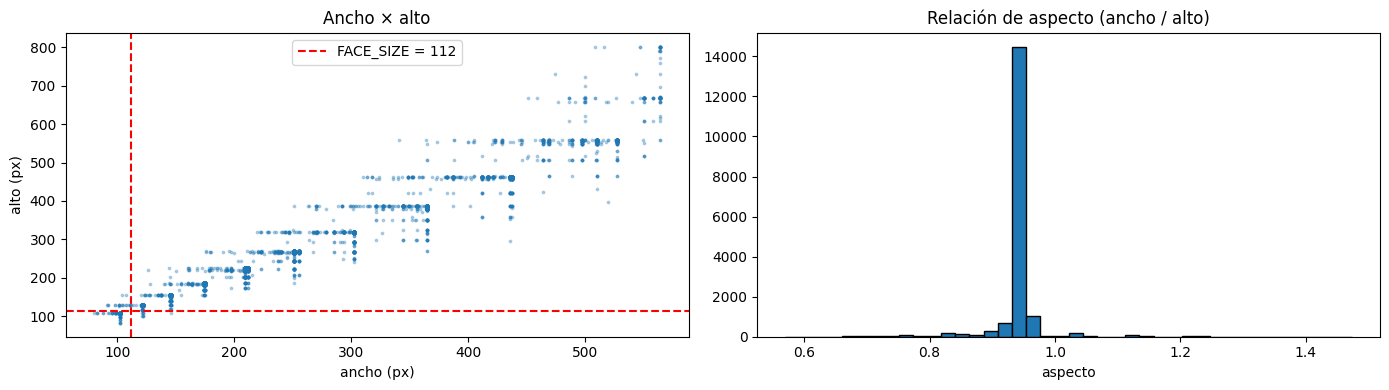

         width   height
count  17534.0  17534.0
mean     211.0    226.0
std      102.0    113.0
min       80.0     82.0
25%      122.0    129.0
50%      175.0    185.0
75%      255.0    268.0
max      564.0    802.0
Imágenes con algún lado < 112px: 2626


In [10]:
from dotenv import dotenv_values
FACE_SIZE = int(dotenv_values(ROOT / ".env.local.example")["FACE_SIZE"])   # el mismo valor que usa la app

readable = dataset[dataset["readable"]]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].scatter(readable["width"], readable["height"], s=3, alpha=0.3)
axes[0].axvline(FACE_SIZE, color="red", ls="--")
axes[0].axhline(FACE_SIZE, color="red", ls="--", label=f"FACE_SIZE = {FACE_SIZE}")
axes[0].set(title="Ancho × alto", xlabel="ancho (px)", ylabel="alto (px)")
axes[0].legend()
axes[1].hist(readable["aspect_ratio"], bins=40, edgecolor="black")
axes[1].set(title="Relación de aspecto (ancho / alto)", xlabel="aspecto")
plt.tight_layout()
plt.show()

print(readable[["width", "height"]].describe().round(0).to_string())
small = (readable[["width", "height"]].min(axis=1) < FACE_SIZE).sum()
print(f"Imágenes con algún lado < {FACE_SIZE}px: {small}")

El tamaño que importa no es el de la imagen sino el de la **cara dentro de la imagen**: ese análisis necesita el detector y va en la sección 2.4.

### Muestra visual

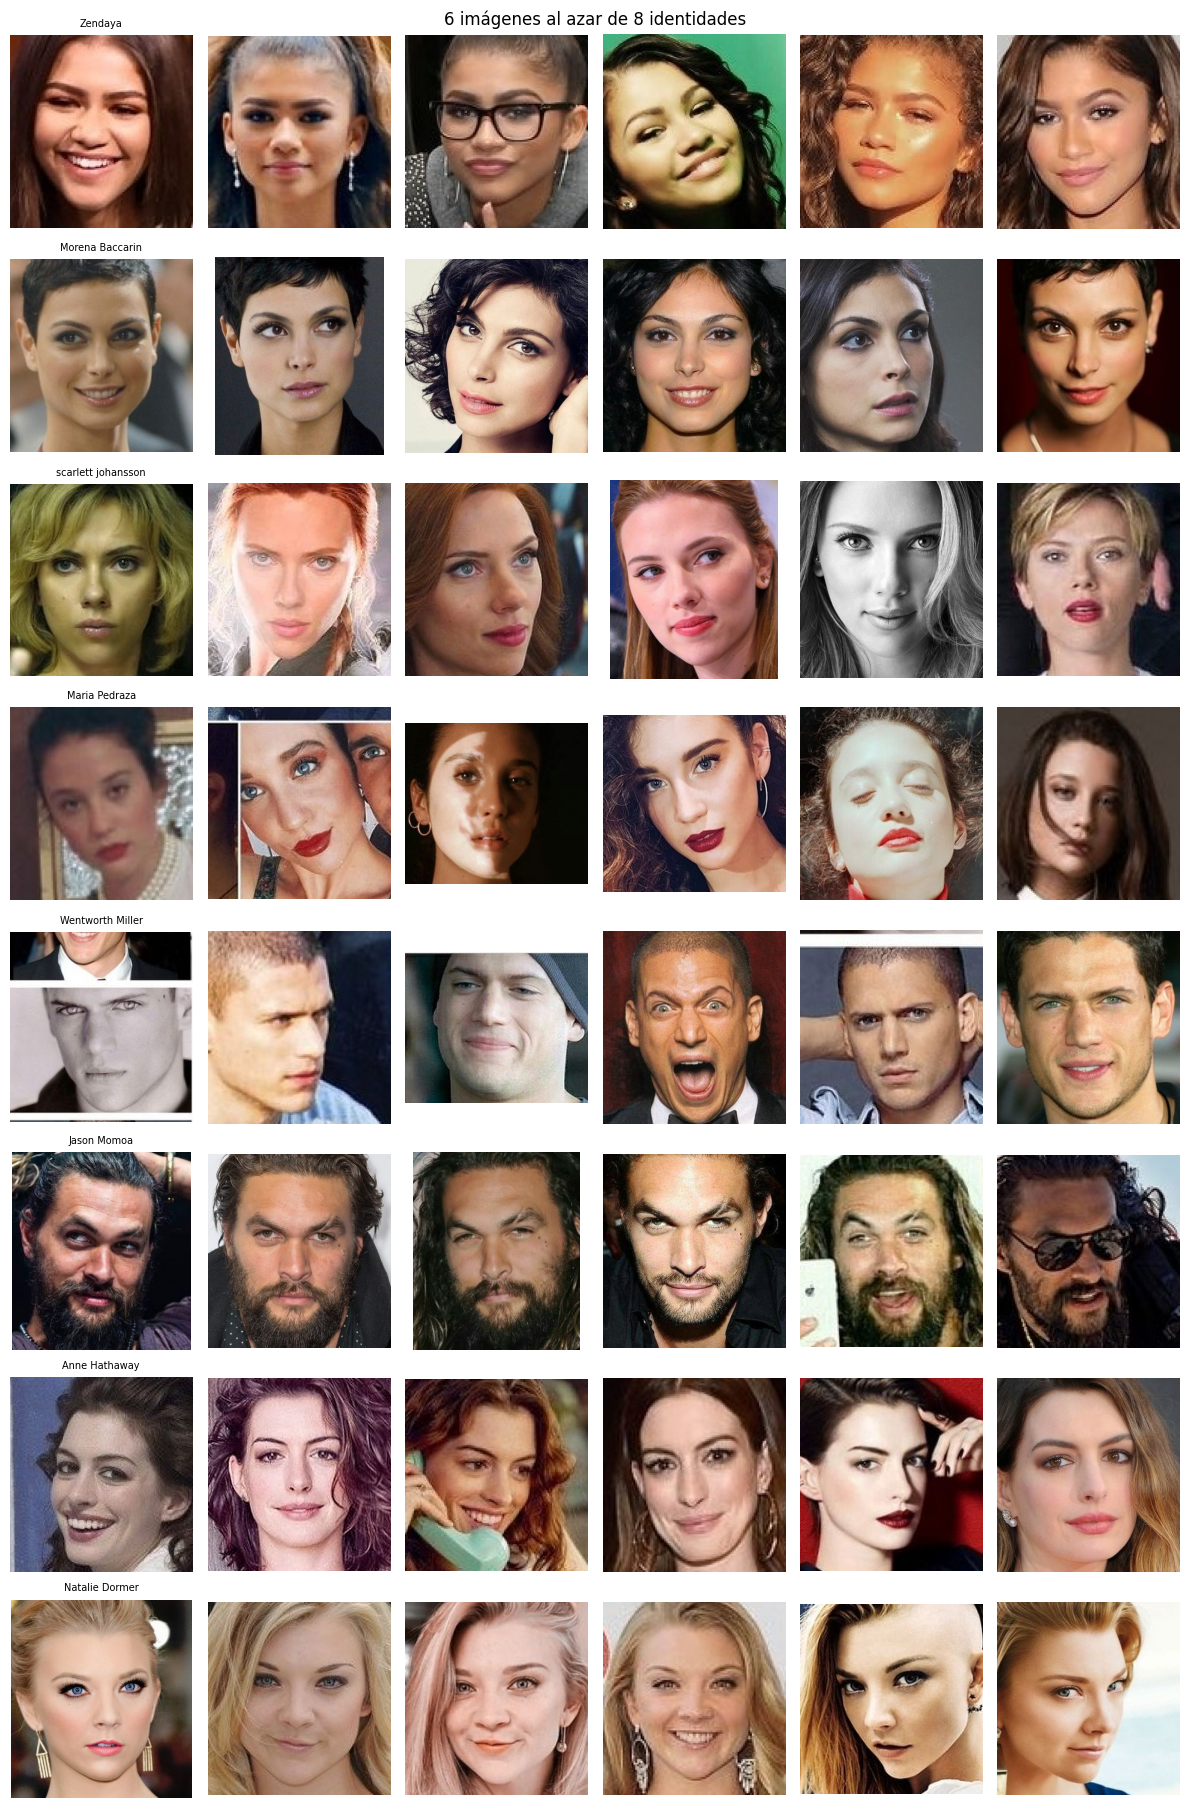

In [11]:
rng = np.random.default_rng(SEED)
sample_ids = rng.choice(dataset["identity"].unique(), size=min(8, dataset["identity"].nunique()), replace=False)
images, titles = [], []
for identity in sample_ids:
    rows = dataset[(dataset["identity"] == identity) & dataset["readable"]].sample(6, random_state=SEED)
    images += [cv2.imread(str(DATASET_ROOT / p)) for p in rows["path"]]
    titles += [identity] + [""] * 5
show_grid(images, titles, ncols=6, size=2.0, suptitle="6 imágenes al azar de 8 identidades")

Las imágenes ya vienen recortadas a la cara (el dataset las publica como “cropped”), con un solo rostro por foto. En la muestra aparecen pocas fotos en blanco y negro (2 de 48). Al estar recortadas, el rostro ocupa casi toda la imagen, así que se espera que la regla de “cara chica” descarte poco y que la de “varias caras” casi no actúe. Lo verificamos en 2.3.

La iluminación, la pose y el blanco y negro se cuantifican sobre la cara alineada, en la sección 2.4.